# 04b. Calibration, abstention and the internal test, all ten runs
1. For every run: temperature and threshold fitted on a stratified half of the validation split (1,605 images), measured on the other half. Mean and spread per backbone.
2. The deployment model (best MobileNetV3-Large by validation macro-F1) and the best ResNet-18 are frozen with their fitted values.
3. The internal test split is read once, for all ten checkpoints (accuracy, macro-F1, seed spread) and in full detail for the two frozen models, with 95% bootstrap intervals over test images.



In [1]:
# Cell 1: environment, Drive, Kaggle
from google.colab import drive
drive.mount("/content/drive")
!pip install --quiet --upgrade kaggle scikit-learn
import os, json, glob, torch, numpy as np, pandas as pd, torch.nn as nn
import matplotlib.pyplot as plt
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")  # Colab Secrets, never in the notebook
!mkdir --parents ~/.kaggle && echo "$KAGGLE_API_TOKEN" > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token
RUNS_DIRECTORY = "/content/drive/MyDrive/cassacheck_runs"
RESULTS_DIRECTORY = "/content/drive/MyDrive/cassacheck_results"
os.makedirs(RESULTS_DIRECTORY, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
CLASS_NAMES = ["CBB", "CBSD", "CGM", "CMD", "healthy"]
print("device:", device)

Mounted at /content/drive
device: cuda


In [2]:
# Cell 2: images and split (the test split is read in cell 7 only)
!kaggle competitions download --competition cassava-leaf-disease-classification --path /content/data
!unzip -q -o /content/data/cassava-leaf-disease-classification.zip "train_images/*" -d /content/data
!wget --quiet --output-document /content/split_v1_seed42.csv https://raw.githubusercontent.com/Justine-abc/cassavacheck/main/data/split_v1_seed42.csv
labels = pd.read_csv("/content/split_v1_seed42.csv")
image_directory = "/content/data/train_images"
validation_frame = labels[labels.split == "validation"].reset_index(drop=True)
test_frame = labels[labels.split == "test"].reset_index(drop=True)
print("validation", len(validation_frame), "| test", len(test_frame), "(not read until cell 7)")

100% 5.76G/5.76G [05:43<00:00, 18.0MB/s]

validation 3210 | test 3210 (not read until cell 7)


In [3]:
# Cell 3: metric functions (ECE with 15 bins, as the proposal states)
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

def expected_calibration_error(probabilities, targets, bins=15):
    confidence, prediction = probabilities.max(1)
    correct = (prediction == targets).float()
    edges = torch.linspace(0, 1, bins + 1); error = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.any(): error += in_bin.float().mean() * (correct[in_bin].mean() - confidence[in_bin].mean()).abs()
    return float(error)

def negative_log_likelihood(probabilities, targets):
    return float(nn.functional.nll_loss(probabilities.clamp_min(1e-9).log(), targets))

def fit_temperature(logits, targets):
    log_temperature = torch.zeros(1, requires_grad=True)
    optimizer = torch.optim.LBFGS([log_temperature], lr=0.1, max_iter=200)
    def closure():
        optimizer.zero_grad(); loss = nn.functional.cross_entropy(logits / log_temperature.exp(), targets); loss.backward(); return loss
    optimizer.step(closure)
    return float(log_temperature.exp())

def selective_metrics(probabilities, targets, threshold):
    confidence, prediction = probabilities.max(1)
    kept = confidence >= threshold
    coverage = float(kept.float().mean())
    selective_accuracy = float((prediction[kept] == targets[kept]).float().mean()) if kept.any() else float("nan")
    abstained_accuracy = float((prediction[~kept] == targets[~kept]).float().mean()) if (~kept).any() else float("nan")
    return coverage, selective_accuracy, abstained_accuracy

TARGET_COVERAGE = 0.80
fit_index, measure_index = train_test_split(np.arange(len(validation_frame)), test_size=0.5, stratify=validation_frame["label"], random_state=42)
print("fit half", len(fit_index), "| measure half", len(measure_index))

fit half 1605 | measure half 1605


In [4]:
# Cell 4: calibration and abstention for every run, fit on the fit half, measured on the measure half
rows = []
for path in sorted(glob.glob(f"{RUNS_DIRECTORY}/*_validation_logits.pt")):
    name = os.path.basename(path).replace("_validation_logits.pt", "")
    backbone, seed = name.rsplit("_seed", 1)
    saved = torch.load(path); logits, targets = saved["logits"], saved["targets"]
    fit_logits, fit_targets = logits[fit_index], targets[fit_index]
    measure_logits, measure_targets = logits[measure_index], targets[measure_index]
    temperature = fit_temperature(fit_logits, fit_targets)
    before = torch.softmax(measure_logits, 1); after = torch.softmax(measure_logits / temperature, 1)
    threshold = float(torch.quantile(torch.softmax(fit_logits / temperature, 1).max(1).values, 1 - TARGET_COVERAGE))
    coverage, selective_accuracy, abstained_accuracy = selective_metrics(after, measure_targets, threshold)
    rows.append({"backbone": backbone, "seed": int(seed), "temperature": round(temperature, 4), "threshold": round(threshold, 4),
                 "ece_before": round(expected_calibration_error(before, measure_targets), 4), "ece_after": round(expected_calibration_error(after, measure_targets), 4),
                 "nll_before": round(negative_log_likelihood(before, measure_targets), 4), "nll_after": round(negative_log_likelihood(after, measure_targets), 4),
                 "accuracy_all": round(float((after.argmax(1) == measure_targets).float().mean()), 4),
                 "realized_coverage": round(coverage, 4), "selective_accuracy": round(selective_accuracy, 4), "abstained_accuracy": round(abstained_accuracy, 4)})
calibration_table = pd.DataFrame(rows).sort_values(["backbone", "seed"]).reset_index(drop=True)
print(calibration_table.to_string(index=False))
print()
print(calibration_table.groupby("backbone")[["temperature", "ece_before", "ece_after", "accuracy_all", "realized_coverage", "selective_accuracy", "abstained_accuracy"]].agg(["mean", "std"]).round(4))
calibration_table.to_csv(f"{RESULTS_DIRECTORY}/calibration_abstention_validation_halves.csv", index=False)

/tmp/ipykernel_1194/1379053304.py:23: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return float(log_temperature.exp())


         backbone  seed  temperature  threshold  ece_before  ece_after  nll_before  nll_after  accuracy_all  realized_coverage  selective_accuracy  abstained_accuracy
mobilenetv3_large     0       1.2838     0.6719      0.0493     0.0197      0.5114     0.4953        0.8299             0.7745              0.9123              0.5470
mobilenetv3_large     1       1.1514     0.6752      0.0249     0.0160      0.4676     0.4616        0.8393             0.7850              0.9214              0.5391
mobilenetv3_large     2       1.3877     0.6877      0.0578     0.0159      0.5148     0.4815        0.8305             0.7813              0.9099              0.5470
mobilenetv3_large     3       1.4021     0.6959      0.0525     0.0194      0.5324     0.4923        0.8405             0.7794              0.9177              0.5678
mobilenetv3_large     4       1.4655     0.6879      0.0671     0.0184      0.5625     0.5040        0.8330             0.8012              0.9028              0.551

In [5]:
# Cell 5: choose the frozen models (best validation macro-F1 per backbone, from notebook 03) and freeze their fitted values
summary = pd.read_csv(f"{RUNS_DIRECTORY}/all_runs_summary.csv")
frozen = {}
for backbone in ["mobilenetv3_large", "resnet18"]:
    best = summary[summary.backbone == backbone].sort_values("validation_macro_f1", ascending=False).iloc[0]
    values = calibration_table[(calibration_table.backbone == backbone) & (calibration_table.seed == int(best.seed))].iloc[0]
    frozen[backbone] = {"seed": int(best.seed), "checkpoint": f"{backbone}_seed{int(best.seed)}_best.pt", "temperature": float(values.temperature), "threshold": float(values.threshold),
                        "validation_macro_f1": float(best.validation_macro_f1)}
    print(backbone, frozen[backbone])
json.dump(frozen, open(f"{RESULTS_DIRECTORY}/frozen_models.json", "w"), indent=2)
print("frozen; nothing below changes these values")

mobilenetv3_large {'seed': 1, 'checkpoint': 'mobilenetv3_large_seed1_best.pt', 'temperature': 1.1514, 'threshold': 0.6752, 'validation_macro_f1': 0.7438944732857783}
resnet18 {'seed': 0, 'checkpoint': 'resnet18_seed0_best.pt', 'temperature': 1.2895, 'threshold': 0.6988, 'validation_macro_f1': 0.7469506768877149}
frozen; nothing below changes these values


In [6]:
# Cell 6: model loading and logits on any frame
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

class CassavaDataset(Dataset):
    def __init__(self, frame, transform): self.frame, self.transform = frame, transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        return self.transform(Image.open(f"{image_directory}/{row.image_id}").convert("RGB")), int(row.label)

eval_transform = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def build_model(backbone):
    if backbone == "mobilenetv3_large":
        network = models.mobilenet_v3_large(weights=None); network.classifier[3] = nn.Linear(network.classifier[3].in_features, 5)
    else:
        network = models.resnet18(weights=None); network.fc = nn.Linear(network.fc.in_features, 5)
    return network.to(device).eval()

def logits_on(frame, backbone, checkpoint):
    network = build_model(backbone); network.load_state_dict(torch.load(f"{RUNS_DIRECTORY}/{checkpoint}", map_location=device))
    loader = DataLoader(CassavaDataset(frame, eval_transform), batch_size=128, num_workers=2)
    logits, targets = [], []
    with torch.no_grad():
        for images, batch_targets in loader:
            logits.append(network(images.to(device)).cpu()); targets.append(batch_targets)
    return torch.cat(logits), torch.cat(targets)

In [7]:
# Cell 7: THE INTERNAL TEST SPLIT, READ ONCE. All ten checkpoints (accuracy, macro-F1), calibrated with their own fitted values.
test_rows = []
test_logits_store = {}
for _, run in calibration_table.iterrows():
    checkpoint = f"{run.backbone}_seed{run.seed}_best.pt"
    logits, targets = logits_on(test_frame, run.backbone, checkpoint)
    test_logits_store[(run.backbone, run.seed)] = (logits, targets)
    before = torch.softmax(logits, 1); after = torch.softmax(logits / run.temperature, 1)
    prediction = after.argmax(1)
    coverage, selective_accuracy, abstained_accuracy = selective_metrics(after, targets, run.threshold)
    test_rows.append({"backbone": run.backbone, "seed": run.seed, "test_accuracy": round(float((prediction == targets).float().mean()), 4),
                      "test_macro_f1": round(float(f1_score(targets, prediction, average="macro")), 4),
                      "test_ece_before": round(expected_calibration_error(before, targets), 4), "test_ece_after": round(expected_calibration_error(after, targets), 4),
                      "test_coverage": round(coverage, 4), "test_selective_accuracy": round(selective_accuracy, 4), "test_abstained_accuracy": round(abstained_accuracy, 4)})
test_table = pd.DataFrame(test_rows)
print(test_table.to_string(index=False)); print()
print(test_table.groupby("backbone")[["test_accuracy", "test_macro_f1", "test_ece_before", "test_ece_after", "test_coverage", "test_selective_accuracy"]].agg(["mean", "std"]).round(4))
test_table.to_csv(f"{RESULTS_DIRECTORY}/internal_test_all_runs.csv", index=False)

         backbone  seed  test_accuracy  test_macro_f1  test_ece_before  test_ece_after  test_coverage  test_selective_accuracy  test_abstained_accuracy
mobilenetv3_large     0         0.8193         0.7065           0.0544          0.0157         0.7888                   0.9001                   0.5177
mobilenetv3_large     1         0.8346         0.7246           0.0294          0.0116         0.7922                   0.9162                   0.5232
mobilenetv3_large     2         0.8343         0.7259           0.0551          0.0164         0.7872                   0.9114                   0.5490
mobilenetv3_large     3         0.8346         0.7269           0.0546          0.0174         0.7794                   0.9069                   0.5791
mobilenetv3_large     4         0.8321         0.7264           0.0649          0.0212         0.7956                   0.9045                   0.5503
         resnet18     0         0.8374         0.7209           0.0420          0.0099  

=== mobilenetv3_large, seed 1, T=1.151, threshold=0.675 (internal test, 3,210 images) ===
accuracy 0.8346 CI (0.8212, 0.8474) | macro-F1 0.7246 CI (0.705, 0.7449)
ECE before 0.0294 | after 0.0116 CI (0.0105, 0.0263)
coverage 0.7922 | selective accuracy 0.9162 CI (0.9044, 0.9265) | abstained accuracy 0.5232
              precision    recall  f1-score   support

         CBB     0.4599    0.6646    0.5436       164
        CBSD     0.7591    0.7012    0.7290       328
         CGM     0.7294    0.7927    0.7597       357
         CMD     0.9629    0.9078    0.9346      1974
     healthy     0.6295    0.6848    0.6559       387

    accuracy                         0.8346      3210
   macro avg     0.7081    0.7502    0.7246      3210
weighted avg     0.8502    0.8346    0.8405      3210



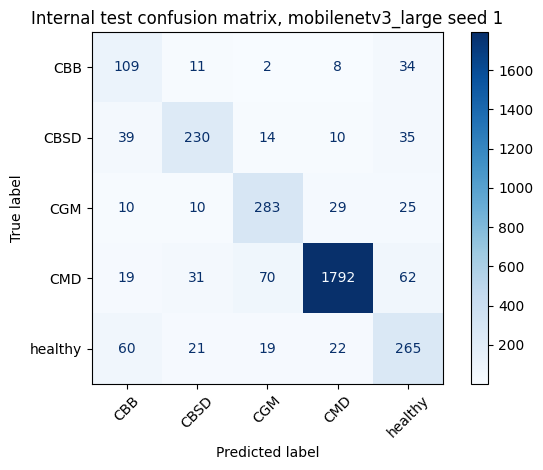

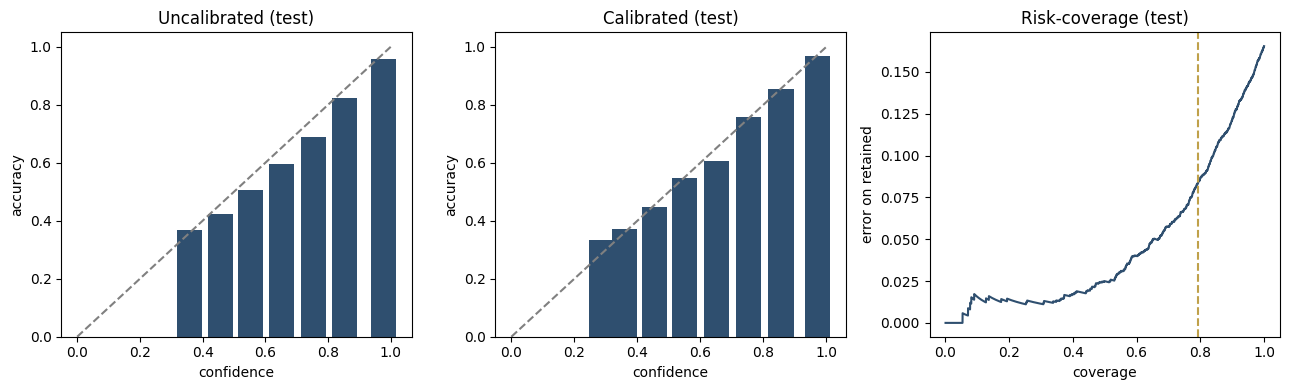

=== resnet18, seed 0, T=1.290, threshold=0.699 (internal test, 3,210 images) ===
accuracy 0.8374 CI (0.8252, 0.8492) | macro-F1 0.7209 CI (0.7003, 0.7412)
ECE before 0.0420 | after 0.0099 CI (0.0102, 0.0255)
coverage 0.7769 | selective accuracy 0.9162 CI (0.9061, 0.9261) | abstained accuracy 0.5628
              precision    recall  f1-score   support

         CBB     0.4804    0.5976    0.5326       164
        CBSD     0.6852    0.7500    0.7162       328
         CGM     0.7277    0.7787    0.7524       357
         CMD     0.9573    0.9189    0.9377      1974
     healthy     0.6811    0.6512    0.6658       387

    accuracy                         0.8374      3210
   macro avg     0.7063    0.7393    0.7209      3210
weighted avg     0.8463    0.8374    0.8410      3210



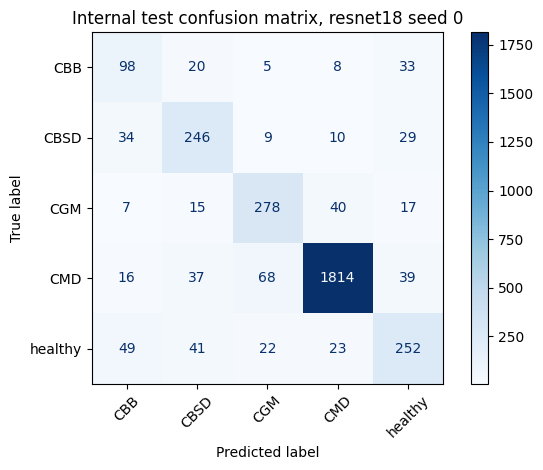

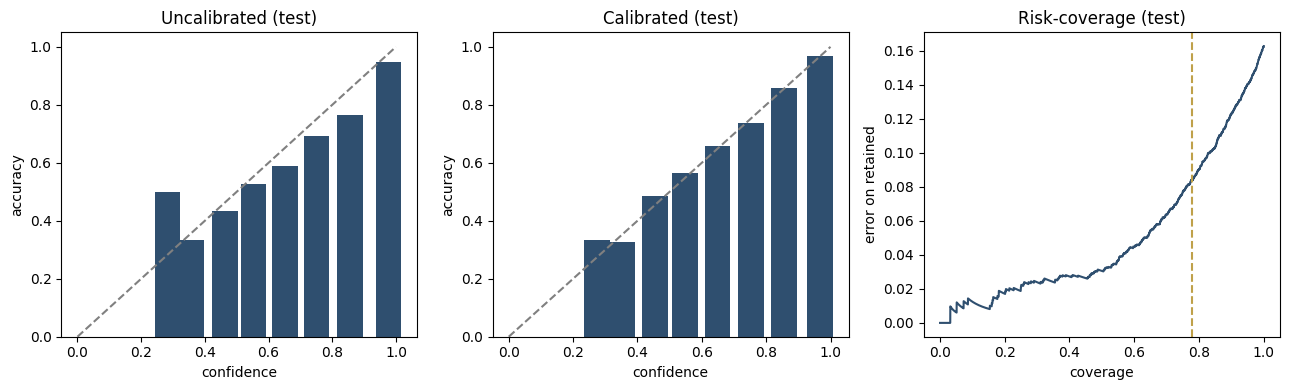

In [8]:
# Cell 8: the two frozen models in detail: per-class report, confusion matrix, bootstrap 95% intervals over test images
rng = np.random.default_rng(42)
def bootstrap_interval(statistic, n_resamples=1000):
    values = [statistic(rng.integers(0, len(test_frame), len(test_frame))) for _ in range(n_resamples)]
    return round(float(np.percentile(values, 2.5)), 4), round(float(np.percentile(values, 97.5)), 4)

detail = {}
for backbone, spec in frozen.items():
    logits, targets = test_logits_store[(backbone, spec["seed"])]
    after = torch.softmax(logits / spec["temperature"], 1); before = torch.softmax(logits, 1)
    prediction = after.argmax(1); confidence = after.max(1).values; kept = confidence >= spec["threshold"]
    correct = (prediction == targets).float().numpy(); targets_np = targets.numpy(); prediction_np = prediction.numpy(); kept_np = kept.numpy()
    accuracy_ci = bootstrap_interval(lambda idx: correct[idx].mean())
    macro_f1_ci = bootstrap_interval(lambda idx: f1_score(targets_np[idx], prediction_np[idx], average="macro"))
    ece_after_ci = bootstrap_interval(lambda idx: expected_calibration_error(after[idx], targets[idx]))
    selective_ci = bootstrap_interval(lambda idx: correct[idx][kept_np[idx]].mean() if kept_np[idx].any() else np.nan)
    print(f"=== {backbone}, seed {spec['seed']}, T={spec['temperature']:.3f}, threshold={spec['threshold']:.3f} (internal test, 3,210 images) ===")
    print(f"accuracy {correct.mean():.4f} CI {accuracy_ci} | macro-F1 {f1_score(targets_np, prediction_np, average='macro'):.4f} CI {macro_f1_ci}")
    print(f"ECE before {expected_calibration_error(before, targets):.4f} | after {expected_calibration_error(after, targets):.4f} CI {ece_after_ci}")
    print(f"coverage {kept.float().mean():.4f} | selective accuracy {correct[kept_np].mean():.4f} CI {selective_ci} | abstained accuracy {correct[~kept_np].mean():.4f}")
    print(classification_report(targets_np, prediction_np, target_names=CLASS_NAMES, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(targets_np, prediction_np), display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=45)
    plt.title(f"Internal test confusion matrix, {backbone} seed {spec['seed']}"); plt.tight_layout(); plt.savefig(f"{RESULTS_DIRECTORY}/test_confusion_{backbone}.png", dpi=150); plt.show()
    # reliability diagram and risk-coverage on the test split
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for axis, (title, probabilities) in zip(axes[:2], (("Uncalibrated", before), ("Calibrated", after))):
        conf, pred = probabilities.max(1); corr = (pred == targets).float(); edges = np.linspace(0, 1, 11); centres, accs = [], []
        for low, high in zip(edges[:-1], edges[1:]):
            in_bin = (conf > low) & (conf <= high)
            if in_bin.any(): centres.append(float(conf[in_bin].mean())); accs.append(float(corr[in_bin].mean()))
        axis.plot([0, 1], [0, 1], "--", color="grey"); axis.bar(centres, accs, width=0.08, color="#2F4F6F"); axis.set_title(f"{title} (test)"); axis.set_xlabel("confidence"); axis.set_ylabel("accuracy")
    order = torch.argsort(confidence, descending=True); sorted_correct = correct[order.numpy()]
    cov = np.arange(1, len(order) + 1) / len(order); risk = 1 - np.cumsum(sorted_correct) / np.arange(1, len(order) + 1)
    axes[2].plot(cov, risk, color="#2F4F6F"); axes[2].axvline(float(kept.float().mean()), color="#BFA14A", linestyle="--"); axes[2].set_xlabel("coverage"); axes[2].set_ylabel("error on retained"); axes[2].set_title("Risk-coverage (test)")
    plt.tight_layout(); plt.savefig(f"{RESULTS_DIRECTORY}/test_calibration_{backbone}.png", dpi=150); plt.show()
    detail[backbone] = {"accuracy": float(correct.mean()), "accuracy_ci": accuracy_ci, "macro_f1": float(f1_score(targets_np, prediction_np, average="macro")), "macro_f1_ci": macro_f1_ci,
                        "ece_before": expected_calibration_error(before, targets), "ece_after": expected_calibration_error(after, targets), "ece_after_ci": ece_after_ci,
                        "coverage": float(kept.float().mean()), "selective_accuracy": float(correct[kept_np].mean()), "selective_accuracy_ci": selective_ci, "abstained_accuracy": float(correct[~kept_np].mean())}
json.dump(detail, open(f"{RESULTS_DIRECTORY}/internal_test_frozen_models.json", "w"), indent=2)

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# Cell 9: deployment artefacts for the repository: the frozen MobileNetV3 checkpoint and its calibration.json
import shutil
spec = frozen["mobilenetv3_large"]
shutil.copy(f"{RUNS_DIRECTORY}/{spec['checkpoint']}", "/content/mobilenetv3_baseline.pt")
json.dump({"temperature": round(spec["temperature"], 4), "threshold": round(spec["threshold"], 4), "target_coverage": TARGET_COVERAGE,
           "fitted_on": "validation split, stratified fit half (1,605 images), seed 42", "measured_on": "validation split, other half; internal test read once in notebook 04b",
           "model": f"MobileNetV3-Large, 8 epochs, seed {spec['seed']}, selected on validation macro-F1 among five seeds"}, open("/content/calibration.json", "w"), indent=2)
print(open("/content/calibration.json").read())
print("download /content/mobilenetv3_baseline.pt and /content/calibration.json into models/ (replacing the two-epoch files); download the CSVs, JSONs and PNGs from", RESULTS_DIRECTORY)

{
  "temperature": 1.1514,
  "threshold": 0.6752,
  "target_coverage": 0.8,
  "fitted_on": "validation split, stratified fit half (1,605 images), seed 42",
  "measured_on": "validation split, other half; internal test read once in notebook 04b",
  "model": "MobileNetV3-Large, 8 epochs, seed 1, selected on validation macro-F1 among five seeds"
}
download /content/mobilenetv3_baseline.pt and /content/calibration.json into models/ (replacing the two-epoch files); download the CSVs, JSONs and PNGs from /content/drive/MyDrive/cassacheck_results


Report mapping: cell 4 is E3 and E4 on validation halves (mean and spread per backbone); cell 7 is E1 for all ten runs on the test split; cell 8 is the frozen models in detail with bootstrap intervals; cell 9 is what the product ships.